### Laboratorium 3 - zadania

In [1]:
import os

import cv2
import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets
from ipywidgets import interact, fixed
from scipy.ndimage import binary_fill_holes
import skimage as ski
from skimage.segmentation import slic, mark_boundaries
from skimage.color import label2rgb
from skimage.morphology import remove_small_objects
from skimage.segmentation import clear_border
from skimage.util import img_as_ubyte
from skimage.feature import peak_local_max

#### Zadanie 1

Dane są obrazy `tabby` i `caries` ([źródło](https://universe.roboflow.com/niu-workespeis/caries-xlrql/dataset/2)). Wykonaj dla nich segmentację przy użyciu algorytmu SLIC. Celem jest uzyskanie **jednolitych**  superpikseli, a więc zawierających tylko fragmenty obiektów lub tylko tła (a nie jednego i drugiego naraz). Przeanalizuj zachowanie algorytmu dla różnej liczby superpikseli i parametru sigma.

Zwróć uwagę, że wynikiem działania scikitowej implementacji SLIC - [`skimage.segmentation.slic`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.slic) - (podobnie jak wielu innych algorytmów klasyfikacyjnych) jest obraz typu `np.int64` przyporządkowujący każdemu pikselowi obrazu wejściowego indeks superpiksela. Takiej reprezentacji oczekuje też funkcja [`mark_boundaries`](https://scikit-image.org/docs/stable/api/skimage.segmentation.html#skimage.segmentation.mark_boundaries).

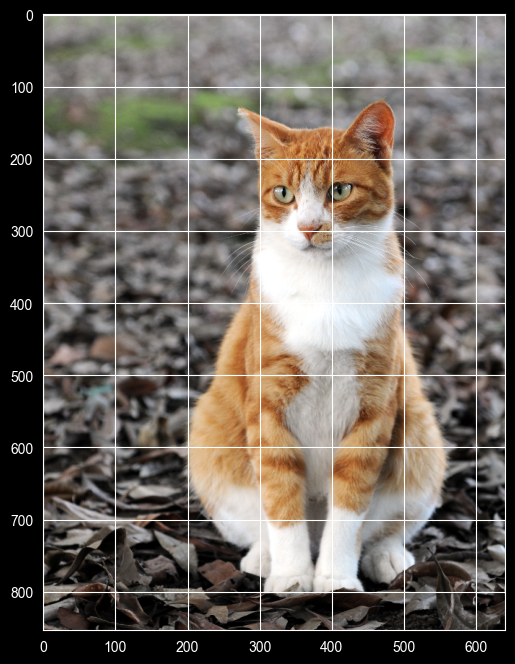

In [2]:
tabby_bgr = cv2.resize(cv2.imread('tabby.jpg'), dsize=None, fx=0.3, fy=0.3)
tabby = tabby_bgr[..., ::-1].copy()
plt.subplots(1,1,figsize=(8,8))[1].imshow(tabby);

In [3]:
def interactive_slic(image, n_segments, compactness, sigma, spacing_y=0.0, spacing_x=0.0):
    if spacing_y == 0 or spacing_x == 0:
        spacing = None
        spacing_title = ""
    else:
        spacing = (spacing_y, spacing_x)
        spacing_title = f", spacing=({spacing_y:.1f}, {spacing_x:.1f})"

    # RGB vs Grayscale
    channel_axis = -1 if image.ndim == 3 else None

    segments = slic(
        image,
        n_segments=n_segments,
        compactness=compactness,
        sigma=sigma,
        spacing=spacing,
        start_label=1,
        channel_axis=channel_axis
    )

    img_boundaries = mark_boundaries(image, segments, color=(1, 0, 0))
    avg_color_img = label2rgb(segments, image, kind='avg', bg_label=0)

    fig, ax = plt.subplots(1, 2, figsize=(14, 6))

    ax[0].imshow(img_boundaries)
    ax[0].set_title(f"Krawędzie (n={n_segments}, comp={compactness:.1f}, $\sigma$={sigma}{spacing_title})")
    ax[0].axis('off')

    ax[1].imshow(avg_color_img)
    ax[1].set_title("Uśrednione kolory superpikseli")
    ax[1].axis('off')

    plt.tight_layout()
    plt.show()

<>:28: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
<>:28: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
C:\Users\pauko\AppData\Local\Temp\ipykernel_12984\430359397.py:28: SyntaxWarning: "\s" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\s"? A raw string is also an option.
  ax[0].set_title(f"Krawędzie (n={n_segments}, comp={compactness:.1f}, $\sigma$={sigma}{spacing_title})")


In [4]:
interact(
    interactive_slic,
    image=fixed(tabby),
    n_segments=widgets.IntSlider(min=20, max=1000, step=20, value=340, description='n_segments:'),
    compactness=widgets.FloatLogSlider(value=10, base=10, min=-2, max=2, step=1, description='compactness:'),
    sigma=widgets.FloatSlider(min=0.0, max=8.0, step=0.5, value=2.5, description='sigma:')
);

interactive(children=(IntSlider(value=340, description='n_segments:', max=1000, min=20, step=20), FloatLogSlid…

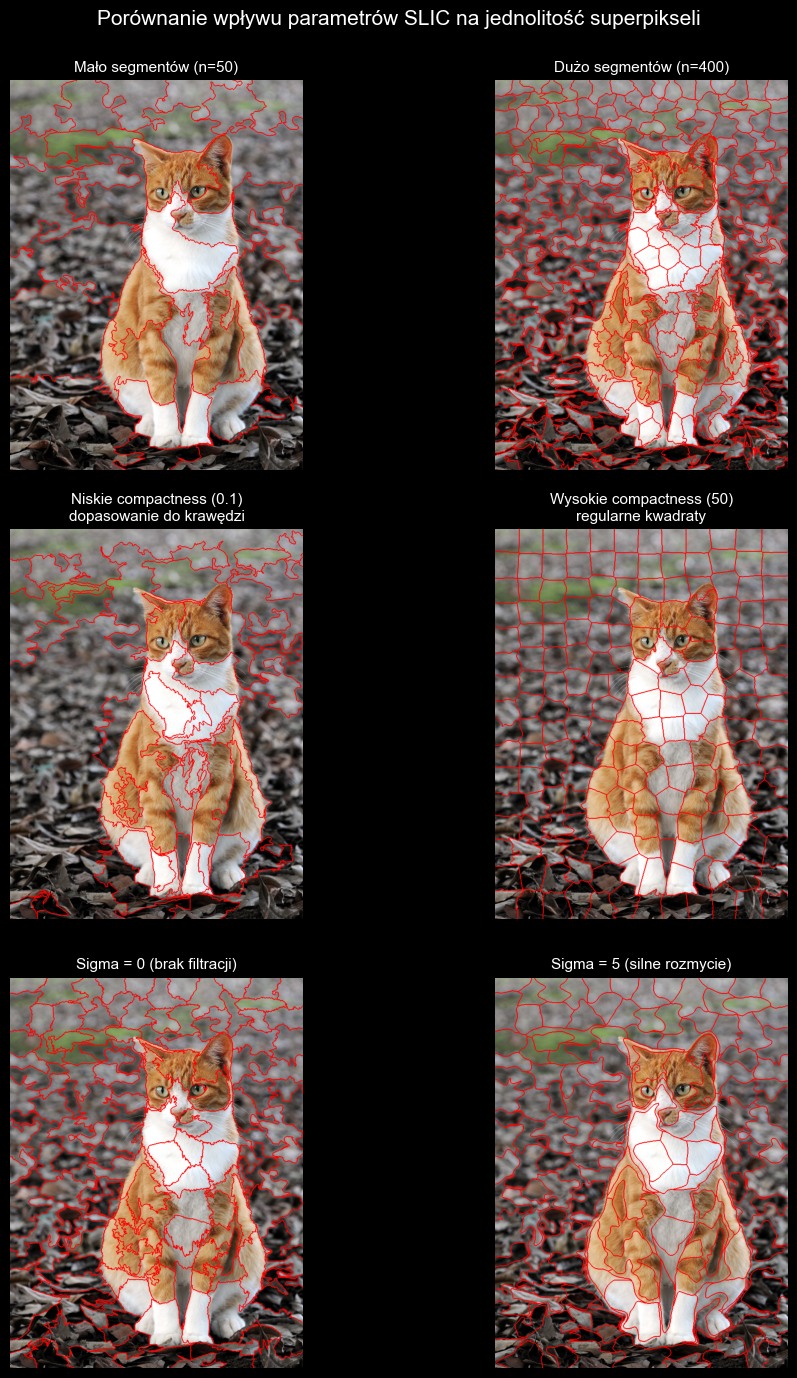

In [5]:
key_configs = [
    {"n_segments": 50,  "compactness": 10.0, "sigma": 1.0, "title": "Mało segmentów (n=50)"},
    {"n_segments": 400, "compactness": 10.0, "sigma": 1.0, "title": "Dużo segmentów (n=400)"},
    {"n_segments": 200, "compactness": 0.1,  "sigma": 1.0, "title": "Niskie compactness (0.1)\ndopasowanie do krawędzi"},
    {"n_segments": 200, "compactness": 50.0, "sigma": 1.0, "title": "Wysokie compactness (50)\nregularne kwadraty"},
    {"n_segments": 200, "compactness": 10.0, "sigma": 0.0, "title": "Sigma = 0 (brak filtracji)"},
    {"n_segments": 200, "compactness": 10.0, "sigma": 5.0, "title": "Sigma = 5 (silne rozmycie)"},
]

fig, axes = plt.subplots(3, 2, figsize=(10, 14))
axes = axes.ravel()

target_img = tabby

for idx, cfg in enumerate(key_configs):
    seg = slic(
        target_img,
        n_segments=cfg["n_segments"],
        compactness=cfg["compactness"],
        sigma=cfg["sigma"],
        start_label=1,
        channel_axis=-1
    )
    res = mark_boundaries(target_img, seg, color=(1, 0, 0))

    axes[idx].imshow(res)
    axes[idx].set_title(cfg["title"], fontsize=11, pad=6)
    axes[idx].axis('off')

plt.suptitle("Porównanie wpływu parametrów SLIC na jednolitość superpikseli", fontsize=15, y=0.99)

plt.subplots_adjust(wspace=0.02, hspace=0.15, left=0.02, right=0.98, top=0.94, bottom=0.02)
plt.show()

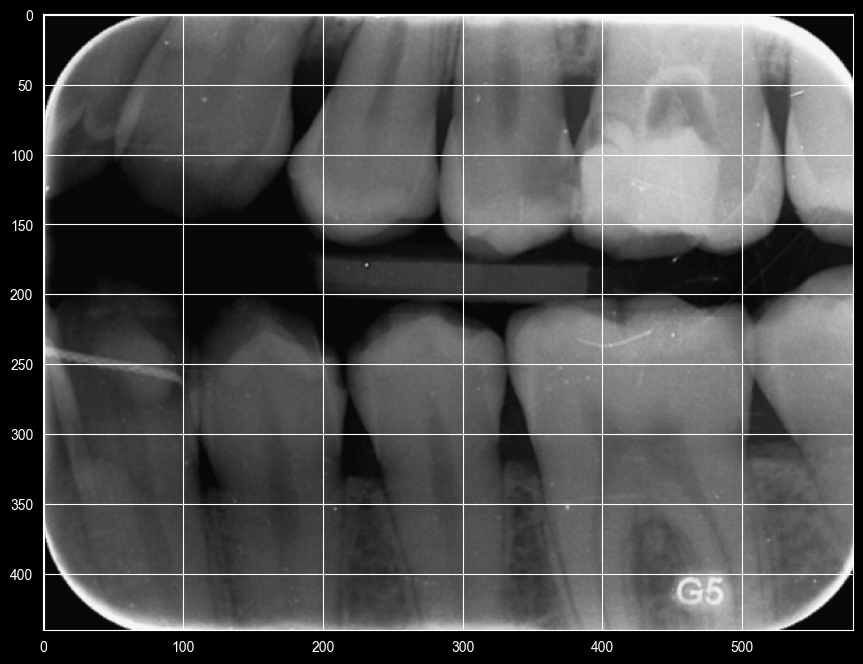

In [6]:
caries = cv2.imread('roboflow-caries-117.jpg')[..., 0]
plt.subplots(1,1,figsize=(12,8))[1].imshow(caries, cmap='gray');

In [7]:
interact(
    interactive_slic,
    image=fixed(caries),
    n_segments=widgets.IntSlider(min=20, max=1000, step=20, value=480, description='n_segments:'),
    compactness=widgets.SelectionSlider(
        options=[0.001, 0.005, 0.01, 0.02, 0.05, 0.1, 1.0, 10.0, 50.0],
        value=0.05,
        description='compactness:'
    ),
    sigma=widgets.FloatSlider(min=0.0, max=8.0, step=0.5, value=1.0, description='sigma:'),
    spacing_y=widgets.FloatSlider(min=0.0, max=5.0, step=0.2, value=0.0, description='spacing Y:'),
    spacing_x=widgets.FloatSlider(min=0.0, max=5.0, step=0.2, value=0.0, description='spacing X:')
);

interactive(children=(IntSlider(value=480, description='n_segments:', max=1000, min=20, step=20), SelectionSli…

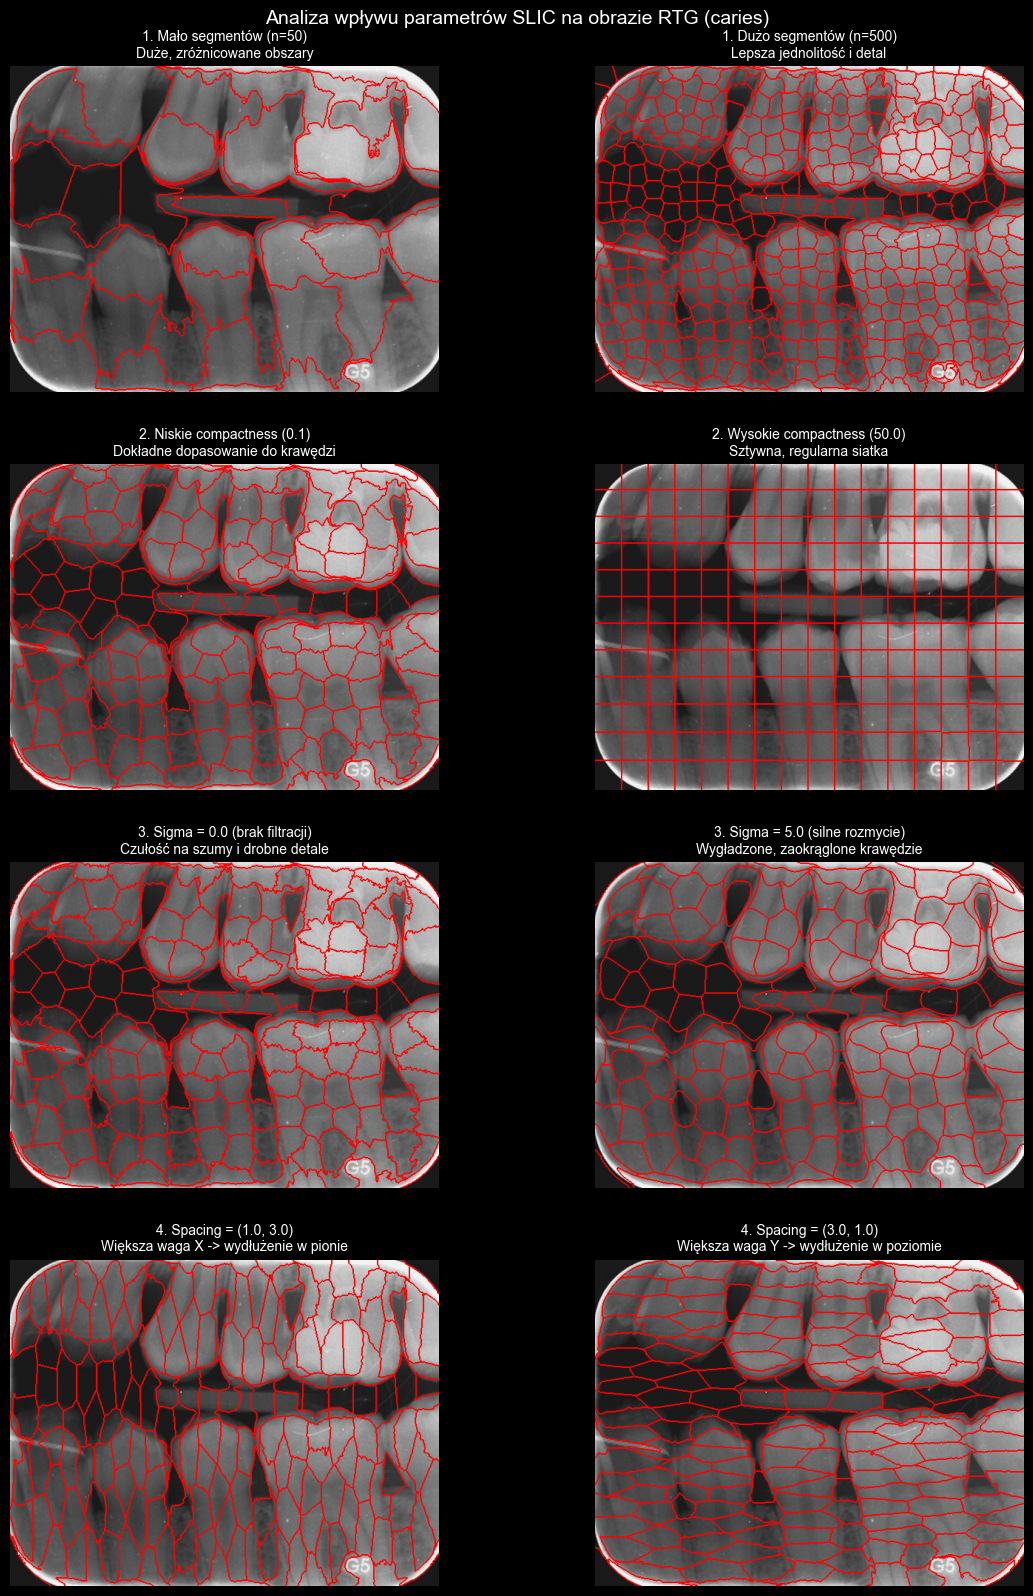

In [8]:
key_configs = [
    {"n_segments": 50,  "compactness": 0.1, "sigma": 1.0, "spacing": None,       "title": "1. Mało segmentów (n=50)\nDuże, zróżnicowane obszary"},
    {"n_segments": 500, "compactness": 0.1, "sigma": 1.0, "spacing": None,       "title": "1. Dużo segmentów (n=500)\nLepsza jednolitość i detal"},

    {"n_segments": 200, "compactness": 0.1,  "sigma": 1.0, "spacing": None,       "title": "2. Niskie compactness (0.1)\nDokładne dopasowanie do krawędzi"},
    {"n_segments": 200, "compactness": 50.0, "sigma": 1.0, "spacing": None,       "title": "2. Wysokie compactness (50.0)\nSztywna, regularna siatka"},

    {"n_segments": 200, "compactness": 0.1, "sigma": 0.0, "spacing": None,       "title": "3. Sigma = 0.0 (brak filtracji)\nCzułość na szumy i drobne detale"},
    {"n_segments": 200, "compactness": 0.1, "sigma": 5.0, "spacing": None,       "title": "3. Sigma = 5.0 (silne rozmycie)\nWygładzone, zaokrąglone krawędzie"},

    {"n_segments": 200, "compactness": 0.1, "sigma": 1.0, "spacing": (1.0, 3.0), "title": "4. Spacing = (1.0, 3.0)\nWiększa waga X -> wydłużenie w pionie"},
    {"n_segments": 200, "compactness": 0.1, "sigma": 1.0, "spacing": (3.0, 1.0), "title": "4. Spacing = (3.0, 1.0)\nWiększa waga Y -> wydłużenie w poziomie"},
]

fig, axes = plt.subplots(4, 2, figsize=(12, 16))
axes = axes.ravel()

channel_axis = -1 if caries.ndim == 3 else None

for idx, cfg in enumerate(key_configs):
    seg = slic(
        caries,
        n_segments=cfg["n_segments"],
        compactness=cfg["compactness"],
        sigma=cfg["sigma"],
        spacing=cfg["spacing"],
        start_label=1,
        channel_axis=channel_axis
    )
    res = mark_boundaries(caries, seg, color=(1, 0, 0))

    axes[idx].imshow(res)
    axes[idx].set_title(cfg["title"], fontsize=10, pad=6)
    axes[idx].axis('off')

plt.suptitle("Analiza wpływu parametrów SLIC na obrazie RTG (caries)", fontsize=14, y=0.995)
plt.subplots_adjust(wspace=0.03, hspace=0.22, left=0.02, right=0.98, top=0.96, bottom=0.01)
plt.show()

#### Zadanie 2

Wykonaj segmentację wododziałową dla obrazów `tabby` i `caries` za pomocą funkcji [`cv2.watershed`](https://docs.opencv.org/4.x/d3/d47/group__imgproc__segmentation.html#ga3267243e4d3f95165d55a618c65ac6e1). Implementacja OpenCV przyjmuje dwa argumenty: obraz wejściowy (8-bit, 3 kanały) i obraz wyjściowy (32-bit, 1 kanał).

Uwaga: obraz wyjściowy musi zawierać oznaczenia początkowe segmentów (_markery_) - to znaczy, że musisz zacząć od przygotowania macierzy markerów. Poprawnie przygotowana macierz zawiera $N$ markerów, tj. pikseli oznaczonych liczbami całkowitymi od 1 do $N$, a wartość pozostałych pikseli wynosi 0. Piksele zerowe zostaną przyporządkowane do grup dookoła markerów.

Sugerowane metody przygotowania markerów (wybierz dwie i porównaj):
* równomierna siatka
* lokalne minima jasności
* manualnie wybrane centra (_segmentacja interaktywna_)

In [43]:
def prepare_watershed_markers(
    image,
    method='distance',       # 'distance', 'grid', 'local_minima', 'manual'
    use_clahe=False,
    blur_ksize=5,
    alpha=0.3,
    min_size=5000,
    min_marker_size=1000,
    clear_edges=False,
    dilate_iter=5,
    grid_step=40,            # 'grid': odstęp między markerami [px]
    min_distance=15,         # 'local_minima': min. odległość między minimami [px]
    marker_radius=3,         # 'grid', 'local_minima', 'manual': promień markera [px]
    manual_points=None,      # 'manual': lista segmentów, każdy = lista punktów (x, y)
):
    steps = {}

    if image.ndim == 3:
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    else:
        gray = image.copy()
    steps['1. Gray'] = gray.copy()

    if use_clahe:
        gray_float = ski.util.img_as_float(gray)
        gray_enhanced = ski.exposure.equalize_adapthist(gray_float, clip_limit=0.03)
        gray = img_as_ubyte(gray_enhanced)
        steps['2. CLAHE'] = gray.copy()

    if blur_ksize > 1:
        gray_blur = cv2.medianBlur(gray, ksize=blur_ksize)
    else:
        gray_blur = gray.copy()
    steps['3. Blur'] = gray_blur.copy()

    h, w = gray.shape
    sure_fg, sure_bg, unknown = None, None, None

    if method == 'distance':
        _, binary = cv2.threshold(gray_blur, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
        steps['4. Otsu Binary'] = binary.copy()

        kernel = np.ones((3, 3), np.uint8)
        opening = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=2)
        steps['5. Opening'] = opening.copy()

        mask_bool = opening > 0
        if min_size > 0:
            mask_bool = remove_small_objects(mask_bool, min_size=min_size)

        mask_filled = binary_fill_holes(mask_bool)
        if clear_edges:
            mask_filled = clear_border(mask_filled)

        mask_ubyte = img_as_ubyte(mask_filled)
        steps['6. Maska (Filled)'] = mask_ubyte.copy()

        dist_transform = cv2.distanceTransform(mask_ubyte, cv2.DIST_L2, 5)
        steps['7. Dist Transform'] = dist_transform.copy()

        _, sure_fg = cv2.threshold(dist_transform, alpha * dist_transform.max(), 255, 0)
        sure_fg = np.uint8(sure_fg)

        if min_marker_size > 0:
            sure_fg_bool = remove_small_objects(sure_fg > 0, min_size=min_marker_size)
            sure_fg = img_as_ubyte(sure_fg_bool)
        steps['8. Sure FG'] = sure_fg.copy()

        sure_bg = cv2.dilate(mask_ubyte, kernel, iterations=dilate_iter)
        steps['9. Sure BG'] = sure_bg.copy()

        unknown = cv2.subtract(sure_bg, sure_fg)
        steps['10. Unknown'] = unknown.copy()

        _, markers = cv2.connectedComponents(sure_fg)
        markers = markers + 1
        markers[unknown == 255] = 0
        steps['11. Markers'] = markers.copy()

    elif method == 'grid':
        markers = np.zeros((h, w), dtype=np.int32)
        r = min(marker_radius, max(grid_step // 2 - 1, 0))

        label = 1
        for y in range(grid_step // 2, h, grid_step):
            for x in range(grid_step // 2, w, grid_step):
                cv2.circle(markers, (int(x), int(y)), int(r), int(label), -1)
                label += 1

        steps['11. Markers (Grid)'] = markers.copy()

    elif method == 'local_minima':
        sigma = max(blur_ksize / 3.0, 1.0)
        smooth = ski.filters.gaussian(gray, sigma=sigma, preserve_range=True)
        steps['3b. Gaussian (minima)'] = smooth.astype(np.uint8)

        grad = ski.filters.sobel(smooth)
        steps['3c. Gradient (minima)'] = (255 * grad / grad.max()).astype(np.uint8)

        coords = peak_local_max(
            -grad,
            min_distance=min_distance,
            exclude_border=False,
        )

        markers = np.zeros((h, w), dtype=np.int32)
        for idx, (y, x) in enumerate(coords, start=1):
            cv2.circle(markers, (int(x), int(y)), int(marker_radius), int(idx), -1)

        steps['11. Markers (Minima)'] = markers.copy()

    elif method == 'manual':
        if not manual_points:
            raise ValueError(
                "Dla method='manual' podaj manual_points, np. "
                "[[(x1, y1), (x2, y2)], [(x3, y3)]] - każdy element listy to jeden segment."
            )

        markers = np.zeros((h, w), dtype=np.int32)
        for label, points in enumerate(manual_points, start=1):
            for (x, y) in points:
                cv2.circle(markers, (int(x), int(y)), int(marker_radius), int(label), -1)

        steps['11. Markers (Manual)'] = markers.copy()

    else:
        raise ValueError(f"Nieznana metoda: {method}")

    return sure_fg, sure_bg, unknown, markers, steps

def color_gradient(image, grad_ksize=3, blur_ksize=5):
    lab = cv2.cvtColor(image, cv2.COLOR_BGR2LAB)
    lab = cv2.GaussianBlur(lab, (blur_ksize, blur_ksize), 0)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (grad_ksize, grad_ksize))
    grads = [cv2.morphologyEx(lab[..., c], cv2.MORPH_GRADIENT, kernel) for c in range(3)]
    return np.max(grads, axis=0)


def gray_gradient(gray, grad_ksize=3, blur_ksize=5):
    smooth = cv2.GaussianBlur(gray, (blur_ksize, blur_ksize), 0)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (grad_ksize, grad_ksize))
    return cv2.morphologyEx(smooth, cv2.MORPH_GRADIENT, kernel)


def run_watershed(image, markers, use_gradient=True, grad_ksize=3, blur_ksize=5):
    if image.ndim == 3:
        img_color = image.copy()
    else:
        img_color = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    if use_gradient:
        if image.ndim == 3:
            grad = color_gradient(image, grad_ksize, blur_ksize)
        else:
            grad = gray_gradient(image, grad_ksize, blur_ksize)
        ws_input = cv2.cvtColor(grad, cv2.COLOR_GRAY2BGR)
    else:
        ws_input = img_color

    markers_ws = markers.astype(np.int32).copy()
    labels = cv2.watershed(ws_input, markers_ws)

    overlay = img_color.copy()
    overlay[labels == -1] = [0, 0, 255]
    return labels, overlay

In [31]:
def _to_rgb(image):
    if image.ndim == 2:
        return cv2.cvtColor(image, cv2.COLOR_GRAY2RGB)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

def rel_points(image, segments):
    h, w = image.shape[:2]
    return [[(int(fx * w), int(fy * h)) for fx, fy in seg] for seg in segments]

def markers_overlay(img_rgb, markers, grow=2):
    shown = ski.morphology.dilation(markers, ski.morphology.disk(grow))
    colored = label2rgb(shown, image=img_rgb, bg_label=0, alpha=1.0,
                        colors=plt.cm.tab10.colors if markers.max() <= 10 else None)
    out = img_rgb.copy().astype(float) / 255.0
    mask = shown > 0
    out[mask] = colored[mask]
    return out


def compare_marker_methods(image, title, configs, use_gradient=True):
    img_rgb = _to_rgb(image)
    n = len(configs)
    fig, axes = plt.subplots(n, 3, figsize=(14, 4.8 * n), squeeze=False,
                             constrained_layout=True)

    for row, (name, params) in enumerate(configs):
        _, _, _, markers, _ = prepare_watershed_markers(image, **params)
        labels, overlay = run_watershed(image, markers, use_gradient=use_gradient)

        n_markers = int(markers.max())
        n_segments = len(np.unique(labels[labels > 0]))

        seg = labels.copy()
        seg[seg < 0] = 0
        seg_rgb = label2rgb(seg, image=img_rgb, kind='avg', bg_label=0)

        axes[row, 0].imshow(markers_overlay(img_rgb, markers))
        axes[row, 0].set_title(f"{name}: markery ({n_markers})", fontsize=11)

        axes[row, 1].imshow(seg_rgb)
        axes[row, 1].set_title(f"{name}: segmenty ({n_segments})", fontsize=11)

        axes[row, 2].imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
        axes[row, 2].set_title(f"{name}: granice", fontsize=11)

        for ax in axes[row]:
            ax.axis('off')

    fig.suptitle(f"Porównanie metod markerów: {title}", fontsize=14)
    plt.show()

C:\Users\pauko\AppData\Local\Temp\ipykernel_12984\3505058445.py:49: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask_bool = remove_small_objects(mask_bool, min_size=min_size)
C:\Users\pauko\AppData\Local\Temp\ipykernel_12984\3505058445.py:65: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  sure_fg_bool = remove_s

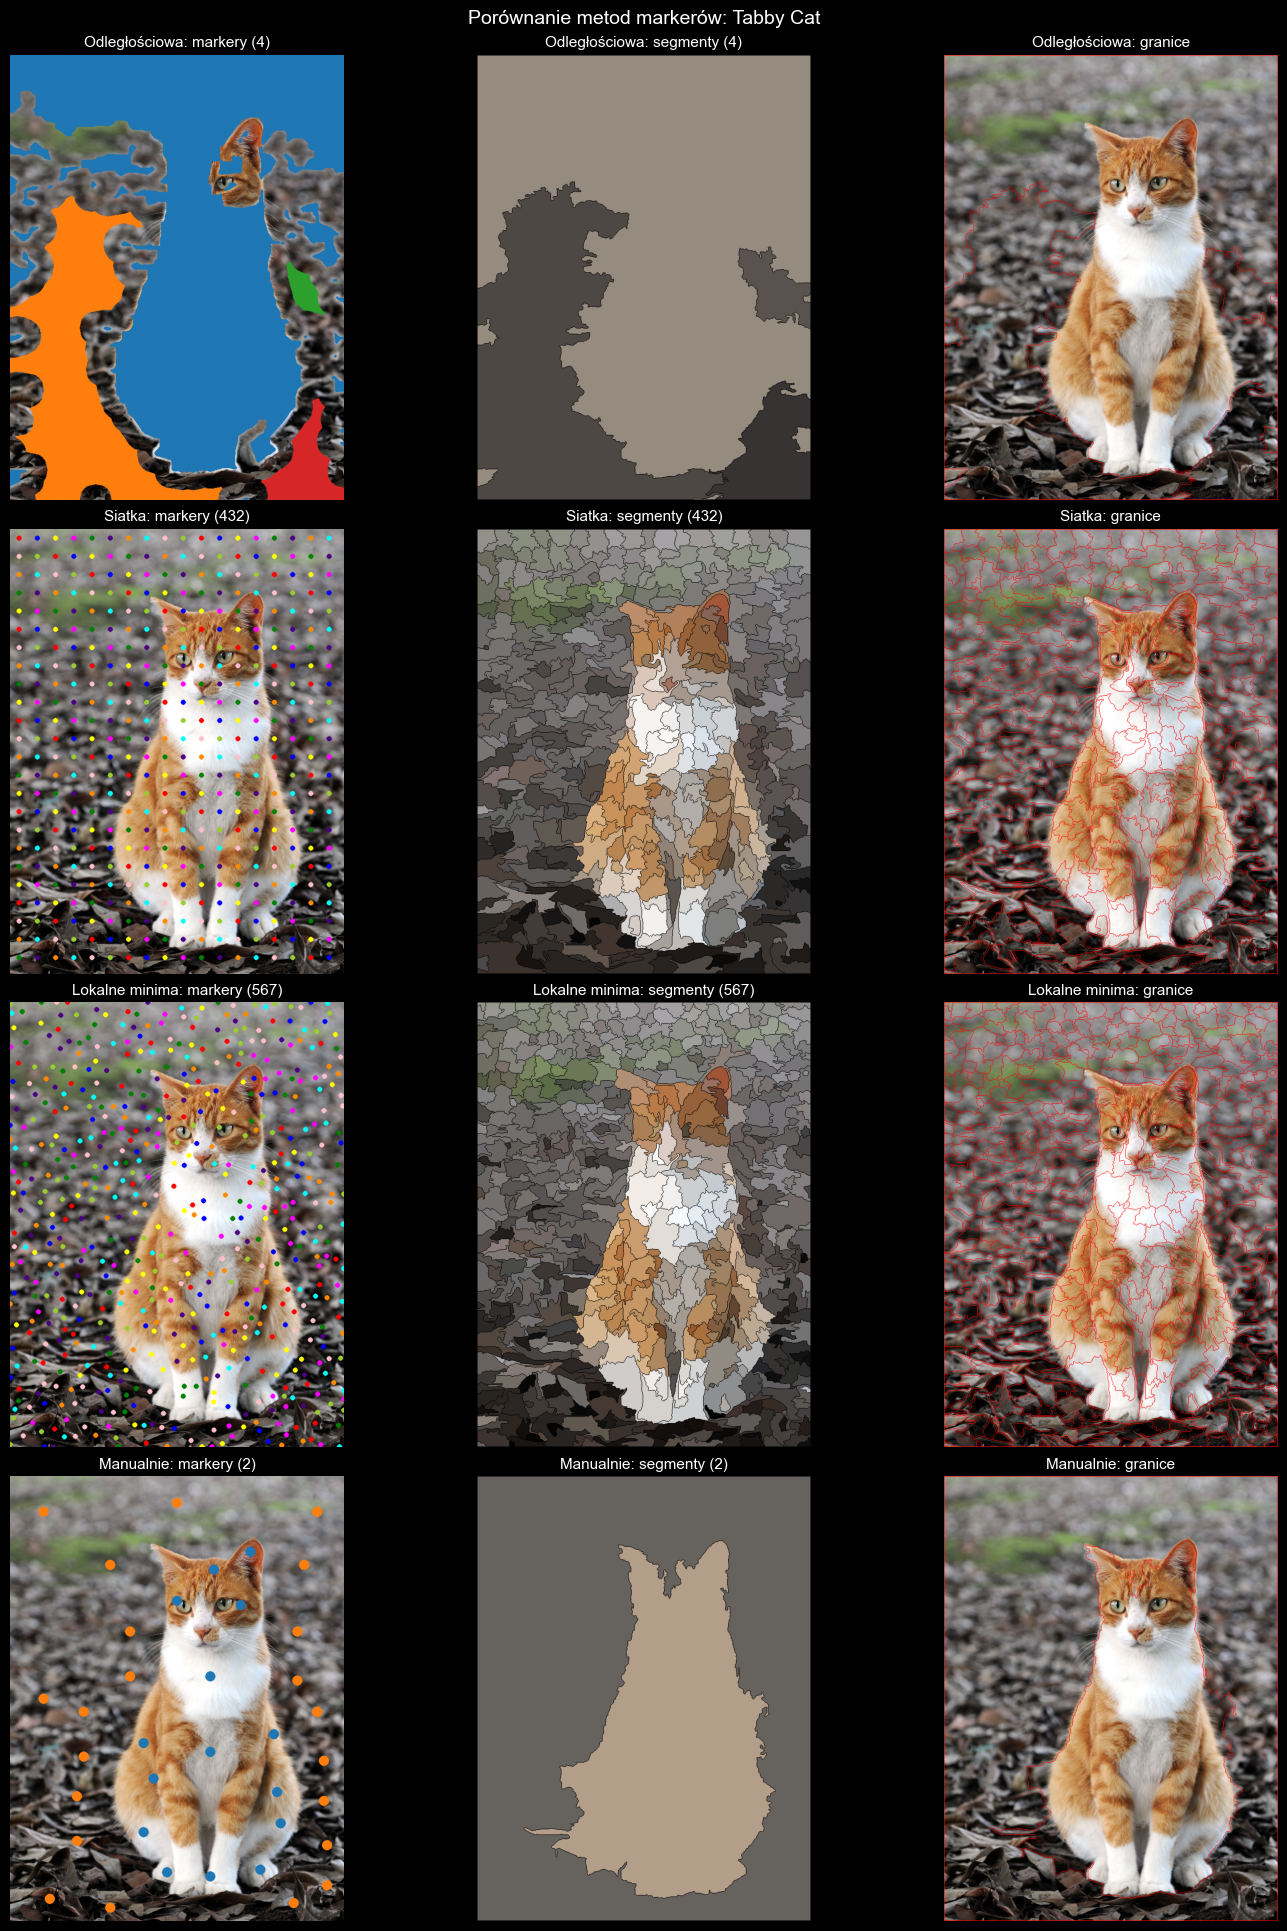

In [41]:
tabby_manual = rel_points(tabby_bgr, [
    [(0.61, 0.21), (0.50, 0.28), (0.69, 0.29), (0.60, 0.45), (0.60, 0.62),
     (0.40, 0.60), (0.79, 0.58), (0.43, 0.68), (0.80, 0.71), (0.40, 0.80),
     (0.81, 0.78), (0.47, 0.89), (0.60, 0.90), (0.75, 0.885),
     (0.72, 0.17)],

    [(0.10, 0.08), (0.50, 0.06), (0.92, 0.08),        # góra
     (0.30, 0.20), (0.88, 0.20),                      # obok głowy
     (0.36, 0.35), (0.86, 0.35),                      # obok szyi
     (0.36, 0.45), (0.86, 0.46),                      # obok piersi
     (0.10, 0.50), (0.22, 0.53), (0.92, 0.53),        # obok boków (tu był wyciek)
     (0.22, 0.63), (0.94, 0.64),
     (0.20, 0.72), (0.94, 0.73),
     (0.20, 0.82), (0.95, 0.83),                      # obok zadu
     (0.12, 0.95), (0.30, 0.97), (0.85, 0.96), (0.95, 0.92)],  # dół
])

compare_marker_methods(tabby_bgr, "Tabby Cat", [
    ("Odległościowa",  dict(method='distance', blur_ksize=9, alpha=0.3, min_size=5000, min_marker_size=1000)),
    ("Siatka",         dict(method='grid', grid_step=35, marker_radius=3)),
    ("Lokalne minima", dict(method='local_minima', blur_ksize=9, min_distance=15, marker_radius=3)),
    ("Manualnie",      dict(method='manual', manual_points=tabby_manual, marker_radius=8)),
])

C:\Users\pauko\AppData\Local\Temp\ipykernel_12984\2657070117.py:49: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  mask_bool = remove_small_objects(mask_bool, min_size=min_size)
C:\Users\pauko\AppData\Local\Temp\ipykernel_12984\2657070117.py:65: FutureWarning: Parameter `min_size` is deprecated since version 0.26.0 and will be removed in 2.0.0 (or later). To avoid this warning, please use the parameter `max_size` instead. For more details, see the documentation of `remove_small_objects`. Note that the new threshold removes objects smaller than **or equal to** its value, while the previous parameter only removed smaller ones.
  sure_fg_bool = remove_s

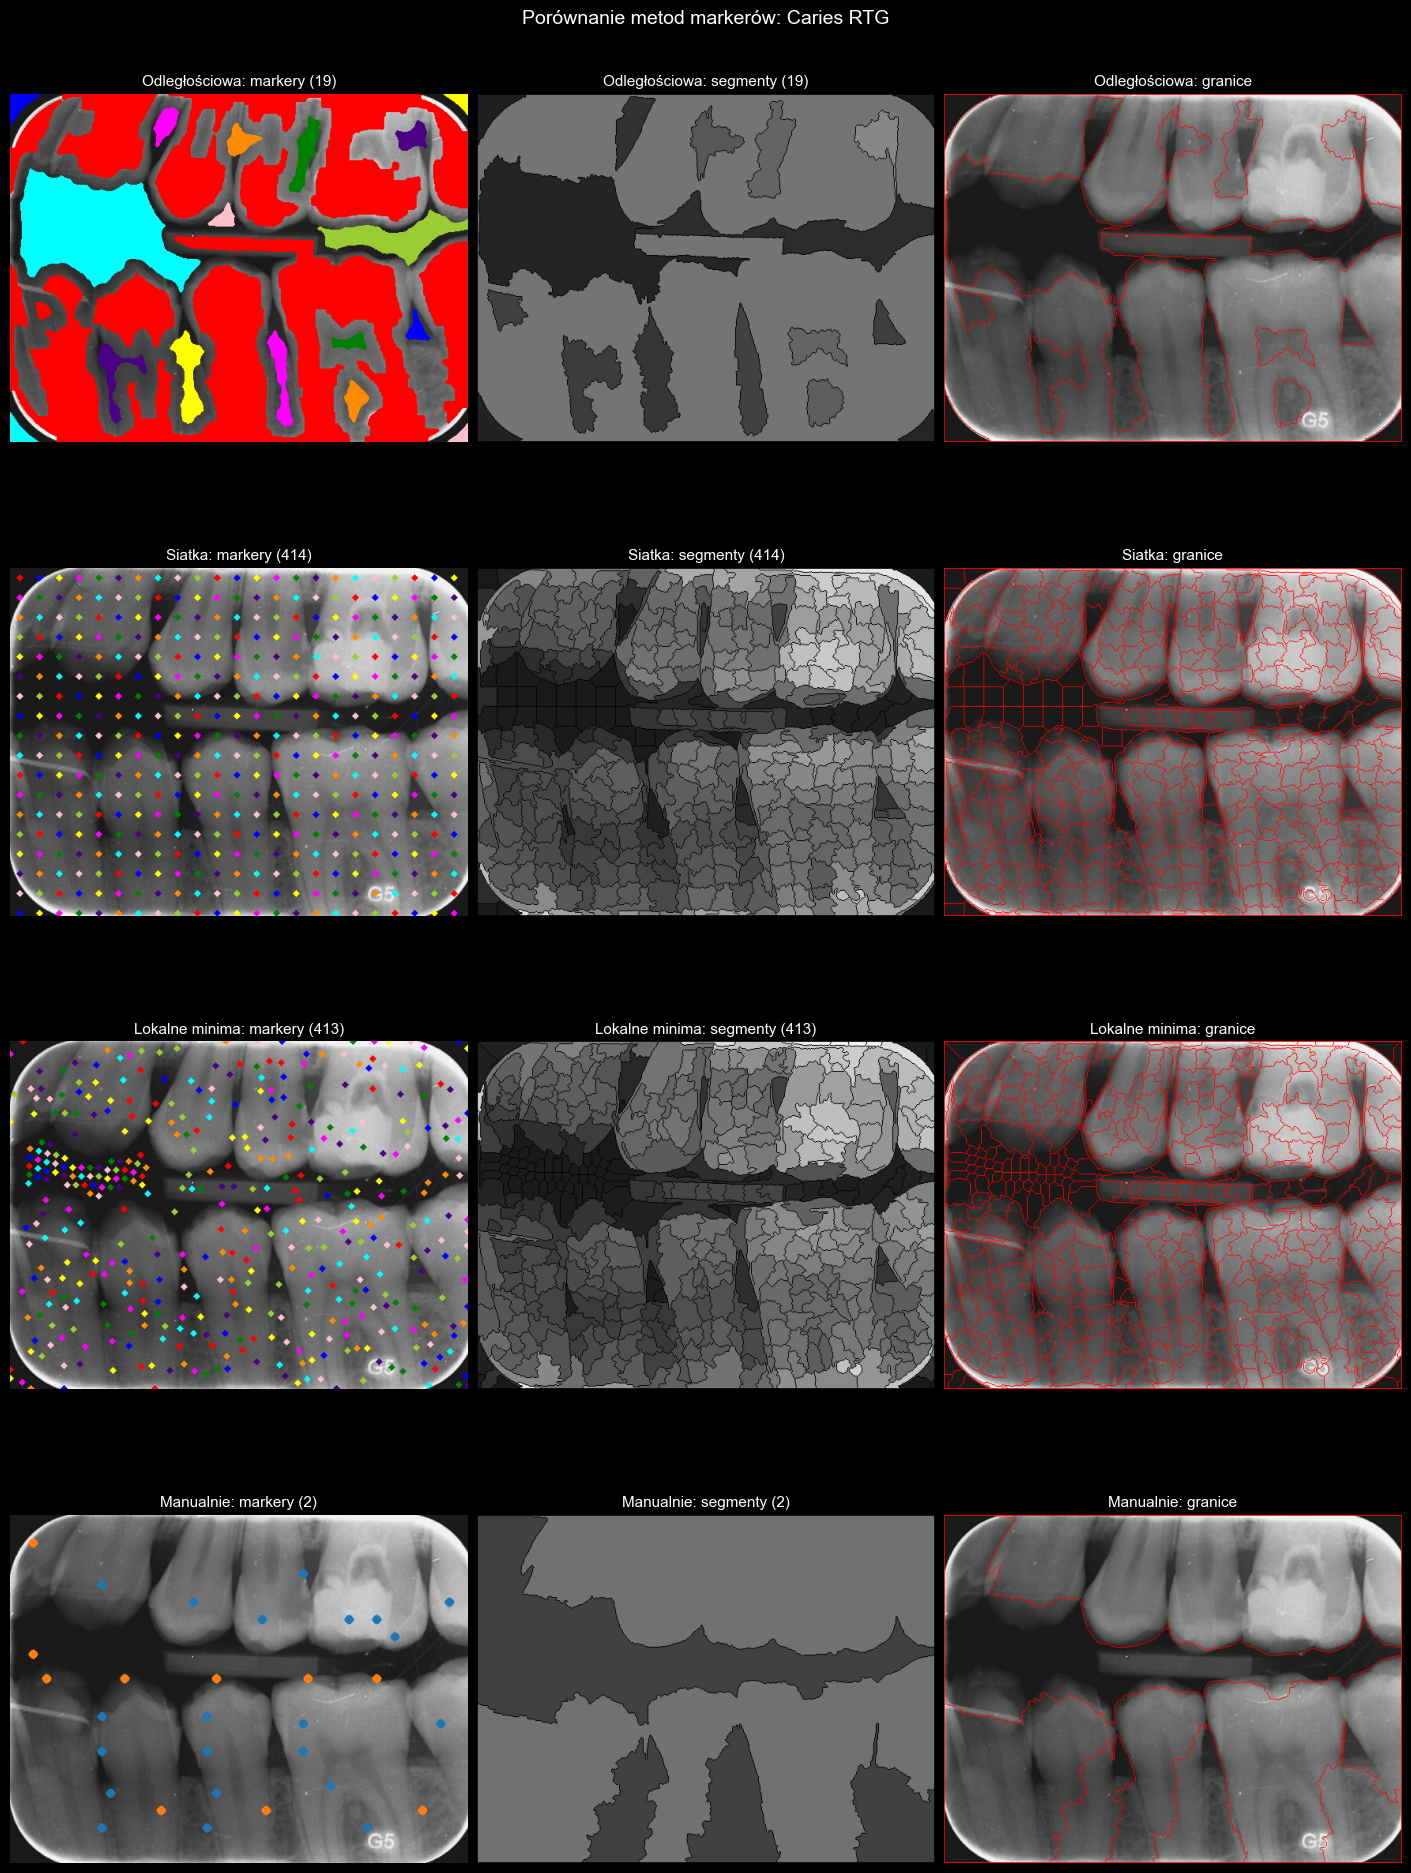

In [70]:
caries_manual = rel_points(caries, [
    [# górne korony i wypełnienie
     (0.80, 0.30), (0.84, 0.35), (0.74, 0.30),
     (0.20, 0.20), (0.40, 0.25), (0.55, 0.30), (0.64, 0.17), (0.96, 0.25),
     # dolne korony
     (0.20, 0.58), (0.20, 0.68),
     (0.43, 0.58), (0.43, 0.68),
     (0.64, 0.60), (0.64, 0.68),
     (0.94, 0.60),
     # dolne korzenie
     (0.22, 0.80), (0.20, 0.90),
     (0.45, 0.80), (0.43, 0.90),
     (0.70, 0.78), (0.78, 0.90)],

    [(0.08, 0.47), (0.25, 0.47), (0.45, 0.47), (0.65, 0.47), (0.80, 0.47),
     (0.05, 0.40), (0.05, 0.08),
     (0.33, 0.85), (0.56, 0.85), (0.90, 0.85)],
])

compare_marker_methods(caries, "Caries RTG", [
    ("Odległościowa", dict(method='distance', use_clahe=True, blur_ksize=3, alpha=0.2, min_size=500, min_marker_size=200)),
    ("Siatka",         dict(method='grid', grid_step=25, use_clahe=False, marker_radius=2)),
    ("Lokalne minima", dict(method='local_minima', use_clahe=False, blur_ksize=5, min_distance=11, marker_radius=2)),
    ("Manualnie",      dict(method='manual', use_clahe=False, manual_points=caries_manual, marker_radius=4)),
])

---

#### Zadanie dodatkowe (dla chętnych, bez oceny)

Dla obrazu `tabby` wykonaj post-processing wybranej metody segmentacji by uzyskać dwa jednorodne obszary: jeden zawierający wyłącznie kota, drugi zawierający wyłącznie tło.

Można to zadanie potraktować jako binaryzację na poziomie superpikseli i zrealizować je za pomocą progowania. 
Można też potraktować je jako klasteryzację superpikseli i wykorzystać np. [`cv2.kmeans`](https://docs.opencv.org/4.x/d5/d38/group__core__cluster.html#ga9a34dc06c6ec9460e90860f15bcd2f88).  
Niezależnie od wybranej ścieżki, konieczne będzie:
1. dobranie odpowiednich (czyli jakich?) parametrów algorytmu segmentacji,
2. opisanie każdego z superpikseli za pomocą jakiejś *cechy/cech* (jakich?), opisującej semantykę rejonów, tak aby na tej podstawie dokonać klasyfikacji.

In [13]:
# zacznij od przygotowania macierzy wejściowej (data) reprezentującej superpiksele jako punkty danych